In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [8]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\21_cmapss_fd001_sample.csv"
df = pd.read_csv(data_path)

In [9]:
df.columns.tolist()

['unit_nr',
 'time_cycles',
 'setting_1',
 'setting_2',
 'setting_3',
 's_2',
 's_3',
 's_4',
 's_7',
 's_11']

In [18]:
e1 = df[df['unit_nr'] == 1].reset_index(drop=True)
e2 = df[df['unit_nr'] == 2].reset_index(drop=True)

In [11]:
corr = e1[sensors].corr()

NameError: name 'sensors' is not defined

In [13]:
((s1 > s1.means() + 2 * s1.std()) | (s1 < s1.means() - 2 * s1.std()))

NameError: name 's1' is not defined

In [14]:
sensors = [
 's_2',
 's_3',
 's_4',
 's_7',
 's_11']

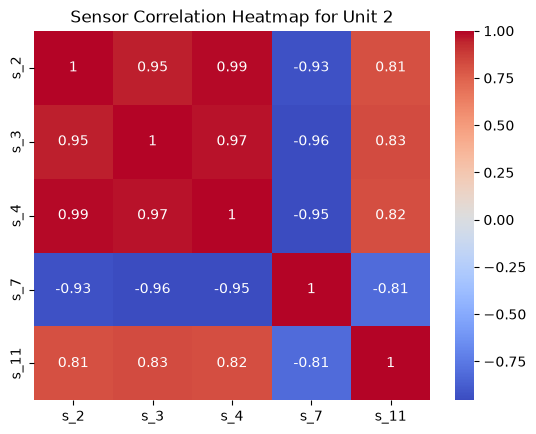

In [20]:
corr = e2[sensors].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Sensor Correlation Heatmap for Unit 2")

plt.show()

In [21]:
#실습2

In [ ]:

high_corr_pairs = []
low_corr_pairs = []
for i in range(len(sensors)):
    for j in range(i+1, len(sensors)):
        if corr.iloc[i, j] >= 0.9:
            high_corr_pairs.append((sensors[i], sensors[j], corr.iloc[i, j]))
        elif corr.iloc[i, j] <= -0.9:
            low_corr_pairs.append((sensors[i], sensors[j], corr.iloc[i, j]))

In [28]:
print("High correlation pairs (>= 0.9):")
for pair in high_corr_pairs:
    print(pair)

print("\nLow correlation pairs (<= -0.9):")
for pair in low_corr_pairs:
    print(pair)

print("\nTotal high correlation pairs:", len(high_corr_pairs))
print("Total low correlation pairs:", len(low_corr_pairs))

High correlation pairs (>= 0.9):
('s_2', 's_3', np.float64(0.95367796559505))
('s_2', 's_4', np.float64(0.9856906736893066))
('s_3', 's_4', np.float64(0.9748481217616536))

Low correlation pairs (<= -0.9):
('s_2', 's_7', np.float64(-0.9324000501550377))
('s_3', 's_7', np.float64(-0.9566875636871429))
('s_4', 's_7', np.float64(-0.9534260870701814))

Total high correlation pairs: 3
Total low correlation pairs: 3


In [ ]:
std20 = e2['s_3'].rolling.std()


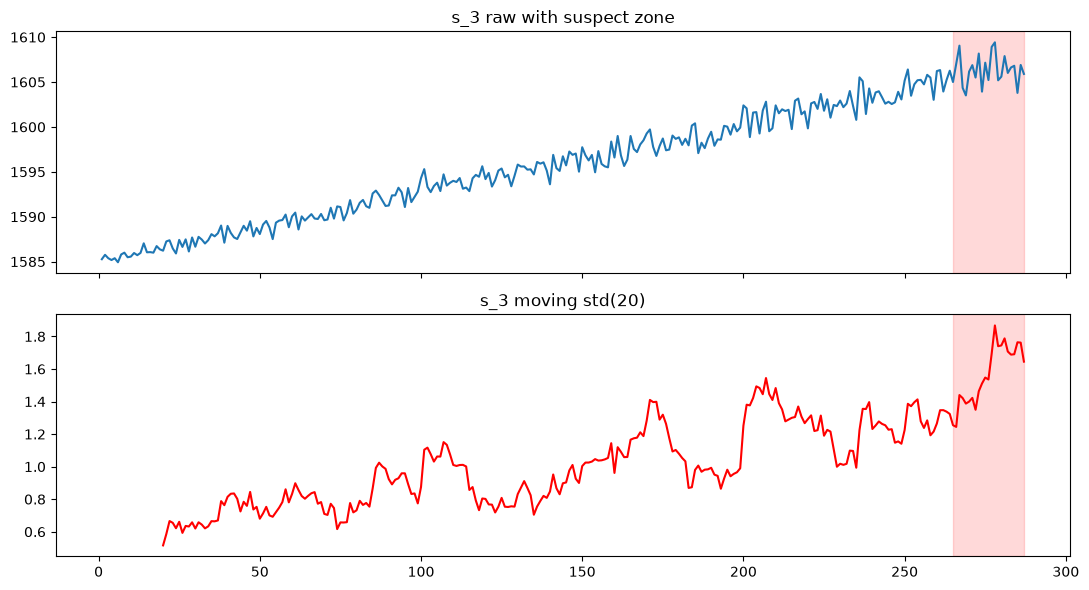

In [29]:
std20 = e2['s_3'].rolling(20).std()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(e2['time_cycles'], e2['s_3']); ax1.axvspan(265, 287, color='red', alpha=0.15)
ax1.set_title('s_3 raw with suspect zone')
ax2.plot(e2['time_cycles'], std20, color='red')
ax2.axvspan(265, 287, color='red', alpha=0.15); ax2.set_title('s_3 moving std(20)')
plt.tight_layout(); plt.show()

In [30]:
s = e2['s_3']
m, sd = s.mean(), s.std()
lower, upper = m - 2*sd, m + 2*sd
print('정상  범위 :', round(lower, 2), '~', round(upper, 2))   # 1583.17 ~ 1608.94
out = ((s > upper) | (s < lower)).sum()
print('벗어난  점 :', int(out))                                # 2
print('초반 50 기준  평균 :', round(s.iloc[:50].mean(), 2))       # 1586.96

정상  범위 : 1583.17 ~ 1608.94
벗어난  점 : 2
초반 50 기준  평균 : 1586.96
